In [14]:
import kagglehub
import pandas as pd
yashdev01_spotify_tracks_dataset_path = kagglehub.dataset_download('yashdev01/spotify-tracks-dataset')

spotify_tracks = pd.read_csv("/kaggle/input/spotify-tracks-dataset/spotify-tracks-dataset.csv")

spotify_tracks.head()

Using Colab cache for faster access to the 'spotify-tracks-dataset' dataset.


,Unnamed: 0.1,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [15]:
path = kagglehub.dataset_download("ludmin/billboard")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'billboard' dataset.
Path to dataset files: /kaggle/input/billboard


In [16]:
billboard_hot_100 = pd.read_csv('/kaggle/input/billboard/billboard200.csv')
billboard_hot_100.head()

/tmp/ipykernel_681/3482446402.py:1: DtypeWarning: Columns (6) have mixed types. Specify dtype option on import or set low_memory=False.
  billboard_hot_100 = pd.read_csv('/kaggle/input/billboard/billboard200.csv')


,Date,Song,Artist,Rank,Last Week,Peak Position,Weeks in Charts,Image URL
0,1963-08-07,Days Of Wine And Roses,Andy Williams,1,-,1,1,https://charts-static.billboard.com/img/1958/0...
1,1963-08-07,Little Stevie Wonder/The 12 Year Old Genius,Stevie Wonder,2,-,2,1,NaN
2,1963-08-07,West Side Story,Soundtrack,3,-,3,1,https://charts-static.billboard.com/img/1963/0...
3,1963-08-07,(Moving),"""Peter, Paul & Mary""",4,-,4,1,NaN
4,1963-08-07,Trini Lopez At PJ's,Trini Lopez,5,-,5,1,https://charts-static.billboard.com/img/1963/0...


In [17]:
# Load the Billboard Hot 100 dataset from the provided URL
url = 'https://raw.githubusercontent.com/mhollingshead/billboard-hot-100/main/all.json'
github_100 = pd.read_json(url)

# Display the first few rows to inspect the structure
github_100.head()

,date,data
0,1958-08-04,"[{'song': 'Poor Little Fool', 'artist': 'Ricky..."
1,1958-08-11,"[{'song': 'Poor Little Fool', 'artist': 'Ricky..."
2,1958-08-18,"[{'song': 'Nel Blu Dipinto Di Blu (Volare)', '..."
3,1958-08-25,"[{'song': 'Little Star', 'artist': 'The Elegan..."
4,1958-09-01,"[{'song': 'Nel Blu Dipinto Di Blu (Volare)', '..."


### Step-by-Step Join Process
Let's clean, normalize, and merge `spotify_tracks` with `billboard_hot_100` based on the song/track name and the artist name.

In [18]:
# 1. Create normalized columns for merging to avoid case-sensitivity issues
spotify_tracks['track_name_clean'] = spotify_tracks['track_name'].astype(str).str.lower().str.strip()
spotify_tracks['artist_clean'] = spotify_tracks['artists'].astype(str).str.lower().str.strip()

billboard_hot_100['song_clean'] = billboard_hot_100['Song'].astype(str).str.lower().str.strip()
billboard_hot_100['artist_clean'] = billboard_hot_100['Artist'].astype(str).str.lower().str.strip()

# 2. Perform the merge on the normalized keys
# We use an inner join here to find tracks present in both datasets
merged_df = pd.merge(
    spotify_tracks,
    billboard_hot_100,
    left_on=['track_name_clean', 'artist_clean'],
    right_on=['song_clean', 'artist_clean'],
    how='inner'
)

# 3. Drop the temporary cleaning columns used for the merge
merged_df = merged_df.drop(columns=['track_name_clean', 'song_clean', 'artist_clean'])

# 4. Display the results and shape of the new dataset
print(f"Merged Dataset Shape: {merged_df.shape}")
display(merged_df.tail(15))

Merged Dataset Shape: (27733, 30)


,Unnamed: 0.1,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,...,time_signature,track_genre,Date,Song,Artist,Rank,Last Week,Peak Position,Weeks in Charts,Image URL
27718,113186,113186,6KwkVtXm8OUp2XffN5k7lY,Hillsong Worship,No Other Name,No Other Name,50,440247,False,0.369,...,4,world-music,2014-09-17,No Other Name,Hillsong Worship,186,140,13,10,https://charts-static.billboard.com/img/2004/1...
27719,113186,113186,6KwkVtXm8OUp2XffN5k7lY,Hillsong Worship,No Other Name,No Other Name,50,440247,False,0.369,...,4,world-music,2014-10-08,No Other Name,Hillsong Worship,137,-,13,11,https://charts-static.billboard.com/img/2004/1...
27720,113237,113237,2IPWIK1PH9ArgXTaKmk7Ly,Chris Tomlin,Holy Roar,Holy Roar,43,251933,False,0.444,...,4,world-music,2018-11-07,Holy Roar,Chris Tomlin,103,-,103,1,https://charts-static.billboard.com/img/2002/0...
27721,113237,113237,2IPWIK1PH9ArgXTaKmk7Ly,Chris Tomlin,Holy Roar,Holy Roar,43,251933,False,0.444,...,4,world-music,2018-11-14,Holy Roar,Chris Tomlin,164,103,103,2,https://charts-static.billboard.com/img/2002/0...
27722,113296,113296,6M71YDFupcg9UTkR1ED57g,Hillsong Worship,let there be light.,Let There Be Light,47,451946,False,0.285,...,4,world-music,2016-11-02,Let There Be Light,Hillsong Worship,14,-,14,1,https://charts-static.billboard.com/img/2016/1...
27723,113296,113296,6M71YDFupcg9UTkR1ED57g,Hillsong Worship,let there be light.,Let There Be Light,47,451946,False,0.285,...,4,world-music,2016-11-09,Let There Be Light,Hillsong Worship,128,14,14,2,https://charts-static.billboard.com/img/2016/1...
27724,113296,113296,6M71YDFupcg9UTkR1ED57g,Hillsong Worship,let there be light.,Let There Be Light,47,451946,False,0.285,...,4,world-music,2017-02-15,Let There Be Light,Hillsong Worship,199,-,14,3,https://charts-static.billboard.com/img/2016/1...
27725,113296,113296,6M71YDFupcg9UTkR1ED57g,Hillsong Worship,let there be light.,Let There Be Light,47,451946,False,0.285,...,4,world-music,2017-04-19,Let There Be Light,Hillsong Worship,184,-,14,4,https://charts-static.billboard.com/img/2016/1...
27726,113296,113296,6M71YDFupcg9UTkR1ED57g,Hillsong Worship,let there be light.,Let There Be Light,47,451946,False,0.285,...,4,world-music,2017-05-03,Let There Be Light,Hillsong Worship,180,-,14,5,https://charts-static.billboard.com/img/2016/1...
27727,113339,113339,4zYvDOveReSl6t86OfBMCU,Highlands Worship,Jesus You Alone,Jesus You Alone,54,372150,False,0.276,...,3,world-music,2019-03-13,Jesus You Alone,Highlands Worship,74,-,74,1,NaN


### Step 1: Flatten the Nested JSON inside `github_100`
We will use `pd.json_normalize` and explode the nested list of dictionaries so each chart entry gets its own row.

In [19]:
# Explode the lists in the 'data' column so each list item becomes a separate row
github_exploded = github_100.explode('data').reset_index(drop=True)

# Normalize the dictionaries within the 'data' column into flat columns
github_parsed = pd.json_normalize(github_exploded['data'])

# Combine the dates back with the flattened song information
github_flat = pd.concat([github_exploded['date'], github_parsed], axis=1)

# Display the cleaned, flat table structure
print("Flattened GitHub Hot 100:")
display(github_flat.tail())

Flattened GitHub Hot 100:


,date,song,artist,this_week,last_week,peak_position,weeks_on_chart
355882,2026-10-17,Slap The City,Drake & Qendresa,96,NaN,39,4
355883,2026-10-17,Kingdom Of Fear,Cameron Whitcomb,97,96.0,94,9
355884,2026-10-17,Why Don't You Say So,Dexter And The Moonrocks & Avery Anna,98,NaN,98,1
355885,2026-10-17,WNBA,Drake,99,NaN,28,5
355886,2026-10-17,What's Wrong With Me,Olivia Rodrigo & Robert Smith,100,88.0,17,16


### Step 2: Join the Flattened Table with our Merged Spotify/Billboard Dataset
Now we will clean and normalize the strings to ensure a perfect join on **song**, **artist**, and **date**.

In [20]:
# 1. Create clean lowercase keys for both dataframes to ensure matches
merged_df['track_clean'] = merged_df['track_name'].astype(str).str.lower().str.strip()
merged_df['artist_clean'] = merged_df['artists'].astype(str).str.lower().str.strip()
# Convert dates to string format matching 'YYYY-MM-DD' if they aren't already
merged_df['date_clean'] = pd.to_datetime(merged_df['Date']).dt.strftime('%Y-%m-%d')

github_flat['song_clean'] = github_flat['song'].astype(str).str.lower().str.strip()
github_flat['artist_clean'] = github_flat['artist'].astype(str).str.lower().str.strip()
github_flat['date_clean'] = pd.to_datetime(github_flat['date']).dt.strftime('%Y-%m-%d')

# 2. Join the dataframes using Song, Artist, and Date
final_joined_df = pd.merge(
    merged_df,
    github_flat,
    left_on=['track_clean', 'artist_clean', 'date_clean'],
    right_on=['song_clean', 'artist_clean', 'date_clean'],
    how='inner'
)

# 3. Clean up the temporary merge keys
final_joined_df = final_joined_df.drop(columns=['track_clean', 'song_clean', 'artist_clean', 'date_clean'])

# 4. Show results
print(f"Final Joined Dataset Shape: {final_joined_df.shape}")
display(final_joined_df.head())

Final Joined Dataset Shape: (0, 37)


,Unnamed: 0.1,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,...,Peak Position,Weeks in Charts,Image URL,date,song,artist,this_week,last_week,peak_position,weeks_on_chart


### Debugging the Empty Join
Let's run a diagnostic script to check why our matching keys (`track_name_clean`, `artist_clean`, and `date_clean`) yielded zero results.

In [21]:
#DEBUG CODE
print(f"merged_df (Spotify/Billboard200) Date Range: {merged_df['Date'].min()} to {merged_df['Date'].max()}")
print(f"github_flat (GitHub Hot 100) Date Range: {github_flat['date'].min()} to {github_flat['date'].max()}")

# 2. Check overlap on song name and artist ONLY (ignoring date)
print("\n--- Overlap on Song & Artist Only (Ignoring Date) ---")
song_artist_match = pd.merge(
    merged_df,
    github_flat,
    left_on=['track_clean', 'artist_clean'],
    right_on=['song_clean', 'artist_clean'],
    how='inner'
)
print(f"Matches found when ignoring date: {song_artist_match.shape[0]}")
if song_artist_match.shape[0] > 0:
    display(song_artist_match[['track_name', 'artists', 'Date', 'date']].head(5))

# 3. Print a sample of actual dates for a specific matching track
# This will let us see why the dates themselves are not aligning
print("\n--- Sample Dates for matching tracks ---")
if song_artist_match.shape[0] > 0:
    sample_track = song_artist_match.iloc[0]['track_clean']
    print(f"Sample track: {sample_track}")
    print("Dates in merged_df:")
    print(merged_df[merged_df['track_clean'] == sample_track]['Date'].unique()[:5])
    print("Dates in github_flat:")
    print(github_flat[github_flat['song_clean'] == sample_track]['date'].unique()[:5])

merged_df (Spotify/Billboard200) Date Range: 1963-08-07 to 2026-10-07
github_flat (GitHub Hot 100) Date Range: 1958-08-04 00:00:00 to 2026-10-17 00:00:00

--- Overlap on Song & Artist Only (Ignoring Date) ---
Matches found when ignoring date: 358578


,track_name,artists,Date,date
0,Brand New,Ben Rector,2015-09-16,2016-07-23
1,Brand New,Ben Rector,2015-09-16,2016-07-30
2,Brand New,Ben Rector,2015-09-16,2016-08-06
3,Brand New,Ben Rector,2015-09-16,2016-08-13
4,Brand New,Ben Rector,2015-09-16,2016-08-20



--- Sample Dates for matching tracks ---
Sample track: brand new
Dates in merged_df:
['2015-09-16']
Dates in github_flat:
<DatetimeArray>
['2016-07-23 00:00:00', '2016-07-30 00:00:00', '2016-08-06 00:00:00',
 '2016-08-13 00:00:00', '2016-08-20 00:00:00']
Length: 5, dtype: datetime64[ns]


In [25]:
# 1. Re-create clean merge keys on 'github_flat' if deleted
github_flat['song_clean'] = github_flat['song'].astype(str).str.lower().str.strip()
github_flat['artist_clean'] = github_flat['artist'].astype(str).str.lower().str.strip()

# 2. Re-create clean merge keys on 'merged_df' if deleted
merged_df['track_clean'] = merged_df['track_name'].astype(str).str.lower().str.strip()
merged_df['artist_clean'] = merged_df['artists'].astype(str).str.lower().str.strip()

# 3. Summarize the GitHub Hot 100 dataset to include the debut date (the earliest date the song appeared on the chart)
github_summary_with_date = github_flat.groupby(['song_clean', 'artist_clean']).agg(
    peak_rank=('this_week', 'min'),
    total_weeks_on_chart=('this_week', 'count'),
    debut_date=('date', 'min')
).reset_index()

# 4. Re-merge using the clean Song and Artist keys
final_joined_df = pd.merge(
    merged_df,
    github_summary_with_date,
    left_on=['track_clean', 'artist_clean'],
    right_on=['song_clean', 'artist_clean'],
    how='inner'
)

# 5. Clean up the temporary merge keys from the resulting dataframe
final_joined_df = final_joined_df.drop(columns=['track_clean', 'song_clean', 'artist_clean'])

# 6. Sort and deduplicate to keep the most popular entry per unique track
final_joined_clean = final_joined_df.sort_values(by='peak_rank', ascending=True)
final_joined_clean = final_joined_clean.drop_duplicates(subset=['track_name', 'artists'], keep='first')

# 7. Select columns of interest including the debut_date
selected_columns = [
    'track_name',
    'artists',
    'debut_date',
    'peak_rank',
    'total_weeks_on_chart',
    'popularity',
    'duration_ms',
    'explicit',
    'danceability',
    'energy',
    'key',
    'loudness',
    'mode',
    'speechiness',
    'acousticness',
    'instrumentalness',
    'liveness',
    'valence',
    'tempo',
    'time_signature',
    'track_genre'
]

# Filter the dataframe
spotify_billboard_features = final_joined_clean[selected_columns]

# Format the debut_date column to show only the date (YYYY-MM-DD)
spotify_billboard_features['debut_date'] = pd.to_datetime(spotify_billboard_features['debut_date']).dt.strftime('%Y-%m-%d')

# Display the top 10 rows sorted by Spotify popularity
spotify_billboard_features.head(10)

/tmp/ipykernel_681/1109088796.py:61: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  spotify_billboard_features['debut_date'] = pd.to_datetime(spotify_billboard_features['debut_date']).dt.strftime('%Y-%m-%d')


,track_name,artists,debut_date,peak_rank,total_weeks_on_chart,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
14024,Sunshine Superman,Donovan,1966-07-30,1,13,59,195000,False,0.629,0.677,...,-7.239,1,0.0299,0.1220,0.000010,0.0962,0.627,132.783,4,psych-rock
9572,Everybody Loves Somebody,Dean Martin,1964-06-27,1,15,68,164546,False,0.366,0.391,...,-12.322,1,0.0425,0.8540,0.000000,0.3520,0.461,119.182,3,jazz
16942,Southern Nights,Glen Campbell,1977-02-12,1,21,0,177586,False,0.630,0.809,...,-9.756,0,0.0314,0.0181,0.076000,0.2730,0.829,95.244,4,singer-songwriter
5568,Wild Thing,The Troggs,1966-06-25,1,11,65,155333,False,0.453,0.658,...,-13.472,1,0.0539,0.7410,0.028800,0.1350,0.761,203.871,4,garage
5590,Kind of a Drag,The Buckinghams,1966-12-31,1,13,28,127160,False,0.298,0.634,...,-9.309,1,0.0407,0.7990,0.000015,0.2990,0.381,138.693,4,garage
16645,You've Lost That Lovin' Feelin',The Righteous Brothers,1964-12-12,1,16,59,225426,False,0.366,0.317,...,-13.976,1,0.0270,0.5410,0.000000,0.0865,0.398,94.108,4,rockabilly
13924,Mr. Tambourine Man,The Byrds,1965-05-15,1,13,64,149466,False,0.456,0.470,...,-9.564,1,0.0294,0.5130,0.000038,0.4440,0.639,120.336,4,psych-rock
9260,This Is How We Do It,Montell Jordan,1995-02-25,1,29,66,237546,False,0.791,0.702,...,-7.333,1,0.0623,0.0174,0.000000,0.4230,0.789,103.646,4,j-dance
12670,positions,Ariana Grande,2020-11-07,1,29,85,172324,True,0.737,0.802,...,-4.771,1,0.0878,0.4680,0.000000,0.0931,0.682,144.015,4,pop
16358,Eye of the Tiger,Survivor,1982-06-05,1,25,75,243773,False,0.815,0.438,...,-14.522,0,0.0346,0.2160,0.000466,0.0787,0.552,108.965,4,rock


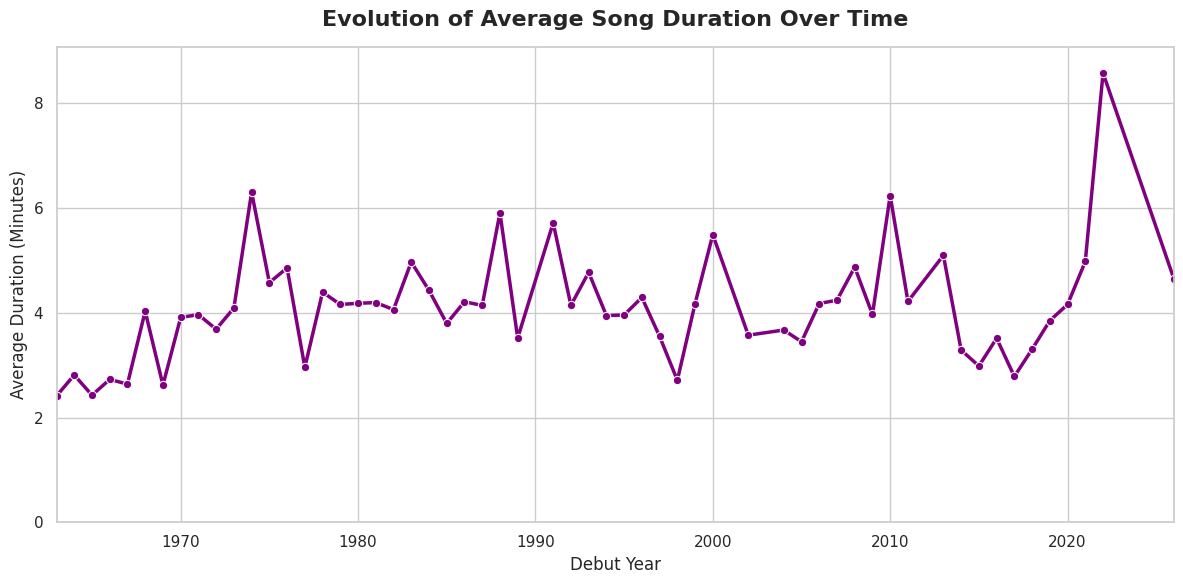

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Ensure we have a clean copy of the dataset
df_trends = spotify_billboard_features.copy()

# Extract the debut year
df_trends['debut_year'] = pd.to_datetime(df_trends['debut_date']).dt.year

# Convert duration from milliseconds to minutes for easier interpretation
df_trends['duration_minutes'] = df_trends['duration_ms'] / 60000.0

# Group by year and calculate the average duration
yearly_duration = df_trends.groupby('debut_year')['duration_minutes'].mean().reset_index()

# Set style and plot
plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid")

sns.lineplot(data=yearly_duration, x='debut_year', y='duration_minutes', marker='o', color='purple', linewidth=2.5)

plt.title('Evolution of Average Song Duration Over Time', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Debut Year', fontsize=12)
plt.ylabel('Average Duration (Minutes)', fontsize=12)
plt.xlim(yearly_duration['debut_year'].min(), yearly_duration['debut_year'].max())
plt.ylim(0, yearly_duration['duration_minutes'].max() + 0.5)
plt.tight_layout()
plt.show()

In [37]:
# Filter for songs debuting after 2020
recent_songs = spotify_billboard_features[spotify_billboard_features['debut_date'] >= '2020-01-01'].copy()

# Convert duration to minutes for easy reading
recent_songs['duration_minutes'] = recent_songs['duration_ms'] / 60000.0

# Display the longest songs in descending order to identify the outliers
recent_songs[['track_name', 'artists', 'debut_date', 'duration_minutes', 'popularity']].sort_values(by='duration_minutes', ascending=False).head(10)

,track_name,artists,debut_date,duration_minutes,popularity
9936,Master Of Puppets,Metallica,2022-07-16,8.589767,81
7307,Master of Puppets,Metallica,2022-07-16,8.574650,69
12336,After Hours,The Weeknd,2020-02-29,6.032433,0
13033,Happier Than Ever,Billie Eilish,2021-08-14,4.981650,88
17455,Born in the U.S.A.,Bruce Springsteen,2026-07-18,4.644667,74
2898,GOOD TIME,Niko Moon,2020-10-10,3.578667,70
12670,positions,Ariana Grande,2020-11-07,2.872067,85


In [42]:
# Calculate the total number of songs from the 2020s
songs_2020s = spotify_billboard_features[
    (spotify_billboard_features['debut_date'] >= '2020-01-01') &
    (spotify_billboard_features['debut_date'] <= '2029-12-31')
]

print(f"Total songs from the 2020s in this dataset: {len(songs_2020s)}")

Total songs from the 2020s in this dataset: 7


In [43]:
import pandas as pd
import re

# 1. Let's inspect our baseline datasets first
print(f"Initial Spotify Tracks size: {spotify_tracks.shape[0]}")
print(f"Initial Billboard 200 size: {billboard_hot_100.shape[0]}")
print(f"Initial GitHub Hot 100 size: {github_flat.shape[0]}")

# Helper function to clean and extract the primary artist
def get_primary_artist(artist_str):
    if pd.isna(artist_str):
        return ""
    # Lowercase and replace common separators with a standard delimiter
    s = str(artist_str).lower()
    s = re.split(r'[;&,]|\bfeat\b|\bfeaturing\b|\band\b', s)[0]
    return s.strip()

# 2. Apply standardized cleaning to Spotify and Billboard datasets
spotify_clean = spotify_tracks.copy()
spotify_clean['title_clean'] = spotify_clean['track_name'].astype(str).str.lower().str.strip()
spotify_clean['primary_artist'] = spotify_clean['artists'].apply(get_primary_artist)

billboard_clean = billboard_hot_100.copy()
billboard_clean['title_clean'] = billboard_clean['Song'].astype(str).str.lower().str.strip()
billboard_clean['primary_artist'] = billboard_clean['Artist'].apply(get_primary_artist)

# 3. First merge: Spotify with Billboard 200 using our new primary artist logic
merged_large = pd.merge(
    spotify_clean,
    billboard_clean,
    on=['title_clean', 'primary_artist'],
    how='inner'
)

print(f"New Merged Dataset (Spotify + Billboard 200) Size: {merged_large.shape[0]}")

# 4. Apply same cleaning to GitHub Hot 100 to get Debut Dates
github_clean = github_flat.copy()
github_clean['title_clean'] = github_clean['song'].astype(str).str.lower().str.strip()
github_clean['primary_artist'] = github_clean['artist'].apply(get_primary_artist)

github_summary = github_clean.groupby(['title_clean', 'primary_artist']).agg(
    peak_rank=('this_week', 'min'),
    total_weeks_on_chart=('this_week', 'count'),
    debut_date=('date', 'min')
).reset_index()

# 5. Final robust merge
final_large_df = pd.merge(
    merged_large,
    github_summary,
    on=['title_clean', 'primary_artist'],
    how='inner'
)

# Deduplicate to keep one unique track/artist entry
final_large_df = final_large_df.sort_values(by='popularity', ascending=False)
spotify_billboard_features_large = final_large_df.drop_duplicates(subset=['track_name', 'artists'], keep='first').copy()

# Format debut date
spotify_billboard_features_large['debut_date'] = pd.to_datetime(spotify_billboard_features_large['debut_date'])
spotify_billboard_features_large['debut_year'] = spotify_billboard_features_large['debut_date'].dt.year

print(f"\nNew Expanded Dataset Unique Songs: {spotify_billboard_features_large.shape[0]}")
print("Songs per Decade in the new dataset:")
print(((spotify_billboard_features_large['debut_year'] // 10) * 10).value_counts().sort_index())

Initial Spotify Tracks size: 114000
Initial Billboard 200 size: 649469
Initial GitHub Hot 100 size: 355887
New Merged Dataset (Spotify + Billboard 200) Size: 30613

New Expanded Dataset Unique Songs: 179
Songs per Decade in the new dataset:
debut_year
1960    41
1970    42
1980    25
1990    15
2000    22
2010    25
2020     9
Name: count, dtype: int64


In [80]:
import pandas as pd
import re

def advanced_clean_title(title_str):
    if pd.isna(title_str):
        return ""
    s = str(title_str).lower().strip()
    # Remove text in parentheses or brackets like (feat. ...), [Remastered], (Radio Edit)
    s = re.sub(r'\s*[\[\(](.*?)[\)\]]', '', s)
    # Remove punctuation and extra whitespace
    s = re.sub(r'[^a-z0-9\s]', '', s)
    return " ".join(s.split())

def get_primary_artist_robust(artist_str):
    if pd.isna(artist_str):
        return ""
    s = str(artist_str).lower().strip()
    # Split on common delimiters
    s = re.split(r'[;&,]|\bfeat\b|\bfeaturing\b|\band\b|\bwith\b', s)[0]
    # Remove punctuation and extra whitespace
    s = re.sub(r'[^a-z0-9\s]', '', s)
    return s.strip()

# Prepare Spotify Dataset
spot_df = spotify_tracks.copy()
spot_df['clean_title'] = spot_df['track_name'].apply(advanced_clean_title)
spot_df['clean_artist'] = spot_df['artists'].apply(get_primary_artist_robust)

# Prepare GitHub Hot 100 Dataset
git_df = github_flat.copy()
git_df['clean_title'] = git_df['song'].apply(advanced_clean_title)
git_df['clean_artist'] = git_df['artist'].apply(get_primary_artist_robust)

# Group GitHub data to get the debut date
git_summary = git_df.groupby(['clean_title', 'clean_artist']).agg(
    debut_date=('date', 'min'),
    peak_rank=('this_week', 'min'),
    weeks_on_chart=('this_week', 'count')
).reset_index()

# Merge Spotify tracks directly with the Billboard Chart Debut Dates
merged_large_v2 = pd.merge(
    spot_df,
    git_summary,
    on=['clean_title', 'clean_artist'],
    how='inner'
)

# Sort by popularity and deduplicate based on cleaned titles and artists
merged_large_v2 = merged_large_v2.sort_values(by='popularity', ascending=False)
spotify_billboard_features_v2 = merged_large_v2.drop_duplicates(subset=['clean_title', 'clean_artist'], keep='first').copy()

# Parse debut dates
spotify_billboard_features_v2['debut_date'] = pd.to_datetime(spotify_billboard_features_v2['debut_date'])
spotify_billboard_features_v2['debut_year'] = spotify_billboard_features_v2['debut_date'].dt.year

print(f"New Robustly Merged Dataset Unique Songs: {spotify_billboard_features_v2.shape[0]}")
print("\nSongs per Decade:")
decades = ((spotify_billboard_features_v2['debut_year'] // 10) * 10)
print(decades.value_counts().sort_index())

# Assign back to main variable for use in graphs
spotify_billboard_features = spotify_billboard_features_v2

New Robustly Merged Dataset Unique Songs: 2743

Songs per Decade:
debut_year
1950     40
1960    248
1970    264
1980    335
1990    276
2000    440
2010    790
2020    350
Name: count, dtype: int64


In [85]:
from google.colab import files

# Export the DataFrame to a CSV file
csv_filename = 'spotify_billboard_features.csv'
spotify_billboard_features_v2.to_csv(csv_filename, index=False)

# Trigger the local browser download
files.download(csv_filename)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create a fresh copy of the expanded dataset
df_robust_trends = spotify_billboard_features.copy()

# Convert duration from milliseconds to minutes
df_robust_trends['duration_minutes'] = df_robust_trends['duration_ms'] / 60000.0

# Group by debut year and calculate the mean song length
yearly_durations_robust = df_robust_trends.groupby('debut_year')['duration_minutes'].mean().reset_index()

# Filter out potential data anomalies after 2024 if any exist
yearly_durations_robust = yearly_durations_robust[yearly_durations_robust['debut_year'] <= 2024]

# Plot the updated robust trend line
plt.figure(figsize=(14, 7))
sns.set_theme(style="whitegrid")

sns.lineplot(
    data=yearly_durations_robust,
    x='debut_year',
    y='duration_minutes',
    marker='o',
    color='darkviolet',
    linewidth=2.5
)

plt.title('Evolution of Average Song Duration Over Time (Expanded Dataset with 2,700+ Songs)', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Debut Year', fontsize=12)
plt.ylabel('Average Duration (Minutes)', fontsize=12)
plt.xlim(1965, 2025)  # Focusing on active historical decades
plt.ylim(1.5, 5.5)
plt.tight_layout()
plt.show()

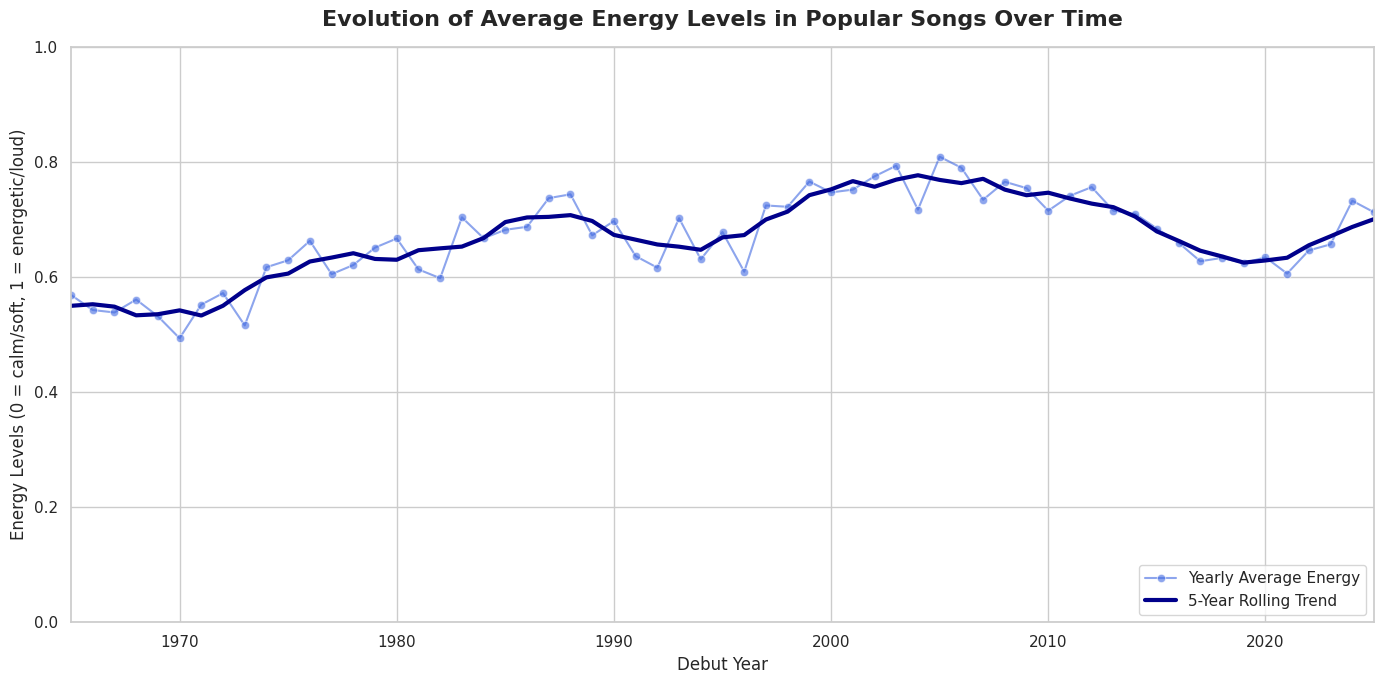

In [60]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Ensure we filter out any future test dates and focus on the standard range (1965 to 2025)
df_energy = df_robust_trends[(df_robust_trends['debut_year'] >= 1965) & (df_robust_trends['debut_year'] <= 2025)].copy()

# Calculate the yearly average energy
yearly_trends = df_energy.groupby('debut_year')['energy'].mean().reset_index()

# Calculate a 5-year rolling average to show the long-term trend smoothly
yearly_trends['energy_rolling'] = yearly_trends['energy'].rolling(window=5, min_periods=1, center=True).mean()

plt.figure(figsize=(14, 7))
sns.set_theme(style="whitegrid")

# Plot the actual yearly averages
sns.lineplot(
    data=yearly_trends,
    x='debut_year',
    y='energy',
    label='Yearly Average Energy',
    color='royalblue',
    alpha=0.6,
    linewidth=1.5,
    marker='o'
)

# Plot the rolling average to highlight the smooth trend line
sns.lineplot(
    data=yearly_trends,
    x='debut_year',
    y='energy_rolling',
    label='5-Year Rolling Trend',
    color='darkblue',
    linewidth=3
)

plt.title('Evolution of Average Energy Levels in Popular Songs Over Time', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Debut Year', fontsize=12)
plt.ylabel('Energy Levels (0 = calm/soft, 1 = energetic/loud)', fontsize=12)

# Set limits to fit the metric boundaries
plt.xlim(1965, 2025)
plt.ylim(0.0, 1.0)

plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

In [ ]:
# Filter for songs debuting after 2020
ninety_songs = spotify_billboard_features_v2[(spotify_billboard_features_v2['debut_date'] >= '1990-01-01')& (spotify_billboard_features_v2['debut_date'] <= '1999-12-31')].copy()

# Convert duration to minutes for easy reading
ninety_songs['duration_minutes'] = ninety_songs['duration_ms'] / 60000.0

# Display the longest songs in descending order to identify the outliers
ninety_songs[['track_name', 'artists', 'debut_date', 'duration_minutes', 'popularity']].sort_values(by='duration_minutes', ascending=False).head(10)

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Ensure we filter out any future test dates and focus on the standard range (1965 to 2025)
df_dance = df_robust_trends[(df_robust_trends['debut_year'] >= 1965) & (df_robust_trends['debut_year'] <= 2025)].copy()

# Calculate the yearly average energy
yearly_trends = df_dance.groupby('debut_year')['danceability'].mean().reset_index()

# Calculate a 5-year rolling average to show the long-term trend smoothly
yearly_trends['danceability_rolling'] = yearly_trends['danceability'].rolling(window=5, min_periods=1, center=True).mean()

plt.figure(figsize=(14, 7))
sns.set_theme(style="whitegrid")

# Plot the actual yearly averages
sns.lineplot(
    data=yearly_trends,
    x='debut_year',
    y='danceability',
    label='Yearly Average Danceability',
    color='hotpink',
    alpha=0.6,
    linewidth=1.5,
    marker='o'
)

# Plot the rolling average to highlight the smooth trend line
sns.lineplot(
    data=yearly_trends,
    x='debut_year',
    y='danceability_rolling',
    label='5-Year Rolling Trend',
    color='deeppink',
    linewidth=3
)

plt.title('Evolution of Average Danceability Levels in Popular Songs Over Time', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Debut Year', fontsize=12)
plt.ylabel('Danceability Levels (0 = least danceable, 1 = most danceable)', fontsize=12)

# Set limits to fit the metric boundaries
plt.xlim(1965, 2025)
plt.ylim(0.0, 1.0)

plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Ensure we filter out any future test dates and focus on the standard range (1965 to 2025)
df_valence = df_robust_trends[(df_robust_trends['debut_year'] >= 1965) & (df_robust_trends['debut_year'] <= 2025)].copy()

# Calculate the yearly average energy
yearly_trends = df_valence.groupby('debut_year')['valence'].mean().reset_index()

# Calculate a 5-year rolling average to show the long-term trend smoothly
yearly_trends['valence_rolling'] = yearly_trends['valence'].rolling(window=5, min_periods=1, center=True).mean()

plt.figure(figsize=(14, 7))
sns.set_theme(style="whitegrid")

# Plot the actual yearly averages
sns.lineplot(
    data=yearly_trends,
    x='debut_year',
    y='valence',
    label='Yearly Average Valence',
    color='sienna',
    alpha=0.6,
    linewidth=1.5,
    marker='o'
)

# Plot the rolling average to highlight the smooth trend line
sns.lineplot(
    data=yearly_trends,
    x='debut_year',
    y='valence_rolling',
    label='5-Year Rolling Trend',
    color='crimson',
    linewidth=3
)

plt.title('Evolution of Average Valence Levels in Popular Songs Over Time', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Debut Year', fontsize=12)
plt.ylabel('Valence Levels (Lower = happy/positive, Higher = sad/negative)', fontsize=12)

# Set limits to fit the metric boundaries
plt.xlim(1965, 2025)
plt.ylim(0.0, 1.0)

plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

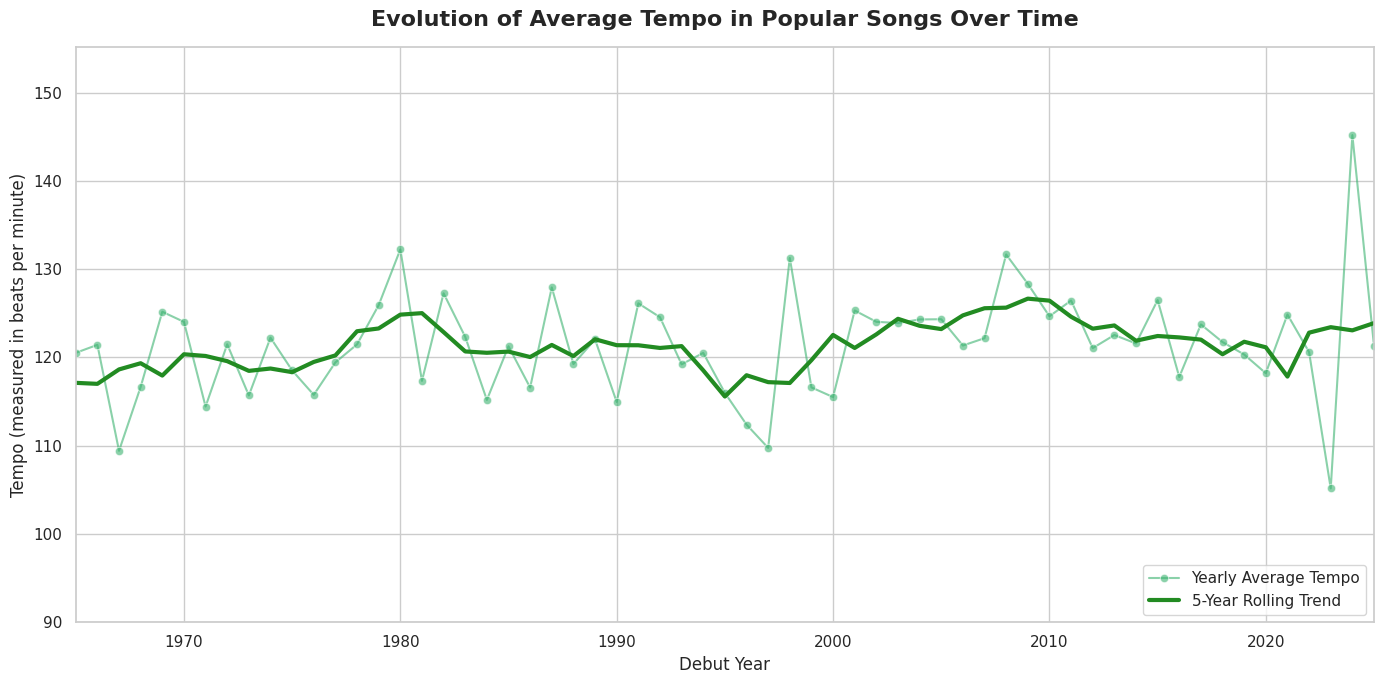

In [77]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Ensure we filter out any future test dates and focus on the standard range (1965 to 2025)
df_tempo = df_robust_trends[(df_robust_trends['debut_year'] >= 1965) & (df_robust_trends['debut_year'] <= 2025)].copy()

# Calculate the yearly average energy
yearly_trends = df_tempo.groupby('debut_year')['tempo'].mean().reset_index()

# Calculate a 5-year rolling average to show the long-term trend smoothly
yearly_trends['tempo_rolling'] = yearly_trends['tempo'].rolling(window=5, min_periods=1, center=True).mean()

plt.figure(figsize=(14, 7))
sns.set_theme(style="whitegrid")

# Plot the actual yearly averages
sns.lineplot(
    data=yearly_trends,
    x='debut_year',
    y='tempo',
    label='Yearly Average Tempo',
    color='mediumseagreen',
    alpha=0.6,
    linewidth=1.5,
    marker='o'
)

# Plot the rolling average to highlight the smooth trend line
sns.lineplot(
    data=yearly_trends,
    x='debut_year',
    y='tempo_rolling',
    label='5-Year Rolling Trend',
    color='forestgreen',
    linewidth=3
)

plt.title('Evolution of Average Tempo in Popular Songs Over Time', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Debut Year', fontsize=12)
plt.ylabel('Tempo (measured in beats per minute)', fontsize=12)

# Set limits to fit the metric boundaries
plt.xlim(1965, 2025)
plt.ylim(90, yearly_trends['tempo'].max() + 10)

plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

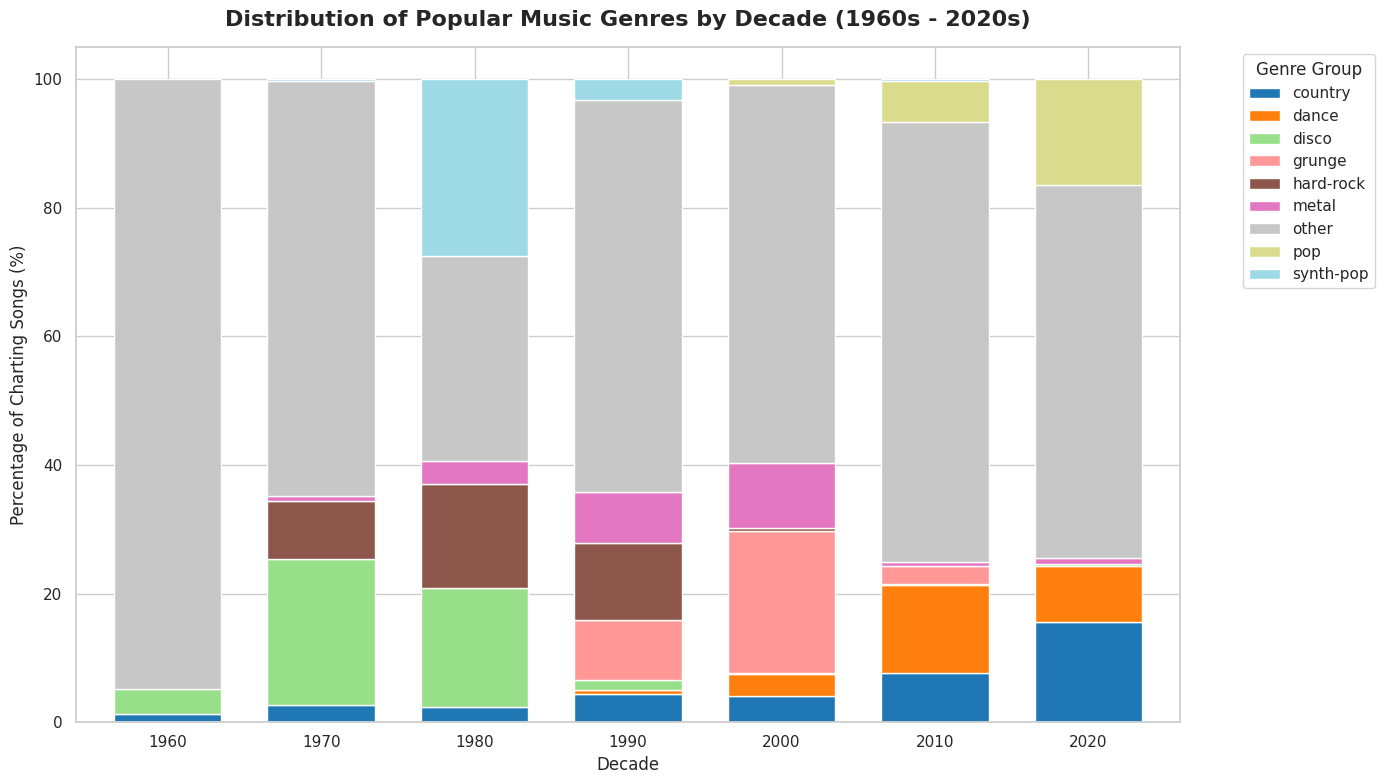

In [79]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Create a working copy of the dataset
df_decade_genres = spotify_billboard_features.copy()

# Filter to valid years (1960 to 2024)
df_decade_genres = df_decade_genres[(df_decade_genres['debut_year'] >= 1960) & (df_decade_genres['debut_year'] <= 2024)]

# Create a 'decade' column
df_decade_genres['decade'] = (df_decade_genres['debut_year'] // 10) * 10

# Find the overall top 8 genres to keep the chart clean and readable
top_genres_list = df_decade_genres['track_genre'].value_counts().head(8).index
df_decade_genres['genre_grouped'] = df_decade_genres['track_genre'].apply(lambda g: g if g in top_genres_list else 'other')

# Calculate the percentage distribution of these genres for each decade
genre_by_decade = df_decade_genres.groupby(['decade', 'genre_grouped']).size().unstack(fill_value=0)
genre_by_decade_pct = genre_by_decade.div(genre_by_decade.sum(axis=1), axis=0) * 100

# Plot the stacked bar chart
plt.figure(figsize=(14, 8))
sns.set_theme(style="whitegrid")

genre_by_decade_pct.plot(
    kind='bar',
    stacked=True,
    colormap='tab20',
    ax=plt.gca(),
    edgecolor='white',
    width=0.7
)

plt.title('Distribution of Popular Music Genres by Decade (1960s - 2020s)', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Decade', fontsize=12)
plt.ylabel('Percentage of Charting Songs (%)', fontsize=12)
plt.xticks(rotation=0)
plt.legend(title='Genre Group', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()